# CIS I — Assignment 1: Pivot Calibration

This notebook walks through the pivot-calibration scenario from the
assignment (Figure 1): a pointer and a calibration object, each
carrying a marker body, observed by an optical tracker. Your job is to
**design** the marker-sphere layouts and workspace placements, then
**calibrate** the pointer's tip position `p_tip` to within about 2mm.

Everything runs against `src.simulation`, a self-contained simulator that plays the role of the physical tracker +
hand-guided robot + calibration sensor described in the handout. It injects measurement noise — your code never sees ground truth
except where explicitly noted for **validation/reporting** in Step 8 (real
hardware wouldn't give you that; the point there is to report your achieved
accuracy, not to use the ground truth in your calibration math itself).



In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(os.path.join(os.getcwd(), "..")))

import numpy as np
from src import simulation
from src import vct3, Rot, Frame

np.set_printoptions(precision=3, suppress=True)


## Step 1: Design the pointer's marker body

Choose approximate local marker-sphere positions `a_ptr,k` (a `List[vct3]`,
relative to the pointer's own coordinate frame) and the pointer tip's
approximate local position `p_tip_approx`. These are your
*nominal design values* — the simulator will independently perturb the
*actual* manufactured positions by a small, noise amount (bounded at
2mm).


In [2]:
ptr_local_positions = [
    vct3(0,0,0),
    vct3(50,0,0),
    vct3(0,80,0),
    vct3(0,0,60)

]
ptr_tip_approx = vct3(0,0,-150)  


## Step 1.1: Design the calibration object's marker body

Same idea, for the calibration object's local marker positions `a_cal,k`.


In [3]:
cal_local_positions = [
    vct3(400,-200,0),
    vct3(400,200,0),
    vct3(-400,-200,0),
    vct3(-400,200,100)
]


## Step 2: Approximate workspace poses

Specify approximate poses (as `Frame` class from src) for the tracking camera
(`F_tracker`) and the calibration object (`F_cal`), relative to the
workspace. The tracker's usable volume is the tetrahedral region in the
handout's Figure 2 (roughly 100-200cm in front of the tracker, widening
from ~120cm to ~200cm across) — place the calibration object, and later
the pointer, so they're inside that volume.


In [4]:
F_tracker_approx = Frame(
    Rot.eye(),
    vct3(-1100, 300, 300)
)

F_cal_approx = Frame(
    Rot.eye(),
    vct3(650, -200, 300)
)

## Step 3: Build the simulation

Fully provided — this just wires up your Step 1/2 design choices through
`simulation`'s `DefineMarkerBody` / `PlaceMarkerBody` / `CreateTracker`
equivalents. `ptr_placed`/`cal_placed` are `PlacedBody` handles: each pairs
a `MarkerBody` with its hidden actual placement, and gets passed to
`simulation.sample_marker_bodies(...)` whenever you want a reading.


In [5]:
ptr_mb = simulation.define_marker_body("ptr_mb", ptr_local_positions)
cal_mb = simulation.define_marker_body("cal_mb", cal_local_positions)

cal_placed = simulation.place_marker_body(cal_mb, F_cal_approx)
# The pointer's own body doesn't have a meaningful "workspace placement" yet
# It moves every time it's hand-guided (Step 4-6). 
# precision="precise" matches a robot-controlled pose rather than a coarsely, manually placed
# static object (see place_marker_body's docstring).
ptr_placed = simulation.place_marker_body(ptr_mb, Frame.eye(), precision="precise")

ptr = simulation.define_pointer("ptr1", ptr_tip_approx, ptr_mb)
trk = simulation.create_tracker("trk1", F_tracker_approx)

print("simulation built:", ptr_mb.name, cal_mb.name, ptr.name, trk.name)


simulation built: ptr_mb cal_mb ptr1 trk1


## Refine Testing

In [6]:
# Save original marker geometry BEFORE refinement
import numpy as np

def marker_array(positions):
    return np.array([
        p.vec.ravel() for p in positions
    ], dtype=float)

ptr_geometry_before = marker_array(
    ptr_mb.nominal_marker_positions
).copy()

cal_geometry_before = marker_array(
    cal_mb.nominal_marker_positions
).copy()


## Step 3.1: Refine `a_ptr,k` / `a_cal,k`

> "Observations of marker positions can be used to determine accurate
> estimates of relative positions a_ptr,k of markers on pointer and
> calibration objects... **Hint**: You probably want to take multiple
> readings in order to reduce the uncertainty associated with the a_k
> values."


In [7]:
from functions.marker_refinement import refine_marker_body

refine_marker_body(trk, ptr_placed)
refine_marker_body(trk, cal_placed)

## Steps 4-6: Collect pivot-calibration observations

For each observation `j`: hand-guide the pointer near the calibration
object at some desired orientation `R_desired,j`, take one simultaneous
tracker reading of *both* bodies, and read the calibration sensor. Loop
skeleton is provided; you choose how many observations to take, how to
vary `R_desired,j`, and what to do when the calibration sensor reports the
tip as out of range (`sense_tip` returns `None`).


In [8]:
N_OBSERVATIONS = 30

def rotation_distance_deg(R1, R2):

    # Calculate relative rotation matrix
    R_relative = R1.matrix.T @ R2.matrix

    # Calculate relative rotation angle
    cos_theta = (np.trace(R_relative) - 1) / 2

    # Avoid numerical errors
    cos_theta = np.clip(cos_theta, -1.0, 1.0)

    theta = np.arccos(cos_theta)

    return np.degrees(theta)

min_angle_diff = 25.0
rng = np.random.default_rng(42)

accepted_rotations = []
accepted_angles = []

F_ptr_list = []
F_cal_list = []
sensed_tip_list = []
for j in range(N_OBSERVATIONS):

    while True:

        rx = int(rng.integers(-70, 71))
        ry = int(rng.integers(-70, 71))
        rz = int(rng.integers(-70, 71))

        R_desired = Rot.xyz_deg(rx, ry, rz)  

        too_close = False

        for R_old in accepted_rotations:
            distance = rotation_distance_deg(R_desired, R_old)

            if distance < min_angle_diff:
                too_close = True
                break

        if too_close:
            continue

        hg = simulation.hand_guide_pointer(ptr, ptr_placed, cal_placed, R_desired)
        obs = simulation.sample_marker_bodies(trk, [ptr_placed, cal_placed])
        sensed = simulation.sense_tip(ptr, hg)

        if sensed is None:
            continue

        F_ptr_list.append(obs["ptr_mb"].frame)
        F_cal_list.append(obs["cal_mb"].frame)
        sensed_tip_list.append(sensed)

        accepted_rotations.append(R_desired)
        accepted_angles.append((rx, ry, rz))

        break


print(f"collected {len(F_ptr_list)} observations")


collected 30 observations


`sensed_tip_list` holds each observation's high-accuracy calibration-sensor
reading `p_sensed,j`: the pointer tip's position relative to the
calibration object's coordinate system, measured to negligible error (or
`None` if that observation ended up outside the sensor's 5mm range). The
hand-guided tip only lands *approximately* at the calibration object's
origin, so the sensor tells you exactly where it actually was for each
observation — an input to Step 7, together with `F_ptr,j` and `F_cal,j`.


## Step 7: Compute a calibrated value for `p_tip`

This is the assignment's core deliverable — implement it yourself and specify the details of implementation in the report.

Each observation `j` gives you three measurements of the same physical
moment: `F_ptr,j` and `F_cal,j` from the tracker, and `p_sensed,j` from the
calibration sensor. Derive how they relate to the unknown `p_tip`, and use
all three in your calibration.

**Corner case to consider**: What are the corner cases you want to analyse here? (e.g. what happens to observations whose `p_sensed,j` is `None`?)

**Minimum data**: how many observations, and what about their rotations,
are needed for the stacked system to actually be solvable? How do you define whether a system is solvable here? Include that in your report


In [9]:
from functions.tip_calibration import compute_pivot_calibration

p_tip_est, p_tip_cov = compute_pivot_calibration(
    F_ptr_list,
    F_cal_list,
    sensed_tip_list
)

In [10]:
print("calibrated p_tip:", p_tip_est)
print("estimated covariance (mm^2):\n", p_tip_cov)
print("estimated std-dev per axis (mm):", np.sqrt(np.diag(p_tip_cov)))


calibrated p_tip: vct3(x=-3.32, y=-2.11, z=-149.39)
Internal Vector:
[[  -3.325]
 [  -2.107]
 [-149.394]]
estimated covariance (mm^2):
 [[ 0.004 -0.    -0.   ]
 [ 0.     0.004 -0.   ]
 [ 0.    -0.     0.004]]
estimated std-dev per axis (mm): [0.06 0.06 0.06]


## Step 8: Validate against test poses

> "**Hint**: You may want to consider placing additional marker bodies
> close to (but not inside) the cube defined by the test volume. However,
> this will also depend on your design for and placement of the
> calibration object."

The nominal test-pose grid is `theta_x, theta_y, theta_z` each in
`{0, +-pi/6, +-pi/3, +-pi/2}` and `p_x, p_y, p_z` each in
`{300, 300+-100, 300+-200}` mm. For each test pose, the assignment requires a
**single observation only** (no averaging).

Think about why the hint suggests an *additional*, nearby reference body?

In [11]:
near_local_positions = [
    vct3(0, 0, 0),
    vct3(400, 0, 0),
    vct3(0, 500, 0),
    vct3(0, 0, 600)
]
F_near_approx = Frame(Rot.eye(),vct3(600, 300, 300))

near_mb = simulation.define_marker_body("near_mb", near_local_positions)
near_placed = simulation.place_marker_body(near_mb, F_near_approx)
refine_marker_body(trk, near_placed)


Refine this new body's geometry the same way you refined the pointer's and
calibration object's (Step 3b) before using it.


Now the single-observation test loop. For each nominal test pose `F_t`:
place the pointer there (small, robot-precision placement error, same as
the real system), take one simultaneous reading of the pointer and your
Step-8 reference body, and predict the tip's position (relative to that
reference body) using your calibrated `p_tip`.

**Ground truth for reporting only**: `PlacedBody.actual_placement` and
`MarkerBody.actual_marker_positions` hold the hidden values the simulator
sampled — you have access to them here only because this notebook doesn't
gate them behind a separate eval mode (per the handout: "During debugging
you will have access to all of the ... values. These will not be available
during evaluation."). Use them *only* to compute and report your achieved
error in this section — using them anywhere in your actual calibration math
(Steps 3b/7) kills the point of the assignment.


In [12]:
from itertools import product
from functions.tip_prediction import (
    predict_tip_position,
    position_error_mm,
    within_tolerance
)
thetas = [0, np.pi / 6, -np.pi / 6, np.pi / 3, -np.pi / 3, np.pi / 2, -np.pi / 2]
offsets = [0, 100, -100, 200, -200]

all_test_poses = [
    Frame(
        Rot.xyz(rx, ry, rz),
        vct3(300 + tx, 300 + ty, 300 + tz)
    )
    for rx, ry, rz in product(thetas, repeat=3)
    for tx, ty, tz in product(offsets, repeat=3)
]

rng = np.random.default_rng(42)

selected_indices = rng.choice(
    len(all_test_poses),
    size=50,
    replace=False
)

test_poses = [
    all_test_poses[i] for i in selected_indices
]

test_results = []
p_tip_true = ptr.get_actual_tip_position().p

for F_t_nominal in test_poses:

    test_placed = simulation.place_marker_body(
        ptr_mb,
        F_t_nominal,
        precision="precise"
    )

    obs = simulation.sample_marker_bodies(
        trk,
        [test_placed, near_placed, cal_placed]
    )

    F_ptr_obs = obs["ptr_mb"].frame
    F_near_obs = obs["near_mb"].frame

    p_predicted = predict_tip_position(
    F_ptr_obs, F_near_obs, p_tip_est
)

    F_ptr_true = test_placed.actual_placement
    F_near_true = near_placed.actual_placement

    p_actual = F_near_true.inv() * F_ptr_true * p_tip_true

    error_mm = position_error_mm(p_predicted, p_actual)

    test_results.append((F_t_nominal, error_mm))

print(f"Completed {len(test_results)} test poses")


Completed 50 test poses


## Achieved performance

Summarize the tip-position error across the test-pose grid against the
handout's 2mm spec.


Test poses: 50
Mean error: 1.4462 mm
RMSE: 1.5172 mm
Maximum error: 2.3831 mm
95th percentile: 2.1773 mm
Within 2 mm: 43/50


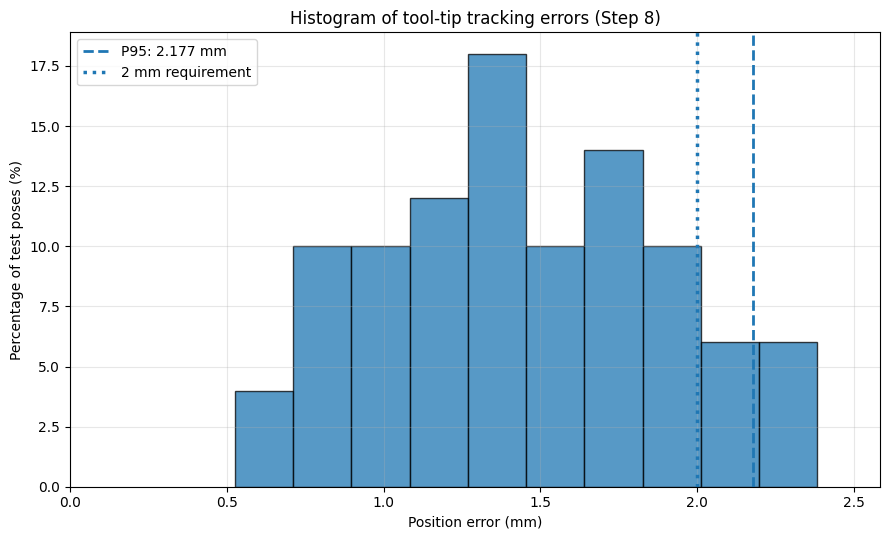

In [13]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt

errors = np.array([result[1] for result in test_results])

mean_error = np.mean(errors)
max_error = np.max(errors)
rmse = np.sqrt(np.mean(errors ** 2))
p95_error = np.percentile(errors, 95)

passed = sum(within_tolerance(e) for e in errors)

print(f"Test poses: {len(errors)}")
print(f"Mean error: {mean_error:.4f} mm")
print(f"RMSE: {rmse:.4f} mm")
print(f"Maximum error: {max_error:.4f} mm")
print(f"95th percentile: {p95_error:.4f} mm")
print(f"Within 2 mm: {passed}/{len(errors)}")


weights = np.ones_like(errors) * 100.0 / len(errors)

plt.figure(figsize=(9, 5.5))
plt.hist(
    errors,
    bins=10,
    weights=weights,
    edgecolor="black",
    alpha=0.75
)

# P95 line
plt.axvline(
    p95_error,
    linestyle="--",
    linewidth=2,
    label=f"P95: {p95_error:.3f} mm"
)

# 2 mm requirement line
plt.axvline(
    2.0,
    linestyle=":",
    linewidth=2.5,
    label="2 mm requirement"
)

plt.xlabel("Position error (mm)")
plt.ylabel("Percentage of test poses (%)")
plt.title("Histogram of tool-tip tracking errors (Step 8)")
plt.legend()
plt.grid(True, alpha=0.3)

plt.xlim(0, max(2.2, max_error + 0.2))

plt.tight_layout()
plt.show()

## calibration test & held-out sensor validation

In [14]:

from itertools import combinations
import numpy as np

# Held-out marker geometry verification
N_GEOMETRY_VALIDATION = 20


def pairwise_distances(points):
    """All pairwise distances for an Nx3 point array."""
    return np.array([
        np.linalg.norm(points[i] - points[j])
        for i, j in combinations(range(len(points)), 2)
    ])


body_configs = {
    "Pointer": {
        "placed": ptr_placed,
        "before": ptr_geometry_before,
        "after": marker_array(ptr_mb.nominal_marker_positions)
    },
    "Calibrator": {
        "placed": cal_placed,
        "before": cal_geometry_before,
        "after": marker_array(cal_mb.nominal_marker_positions)
    }
}

geometry_results = {}

# Collect new observations not used in refinement
for name, config in body_configs.items():

    placed = config["placed"]
    d_before = pairwise_distances(config["before"])
    d_after = pairwise_distances(config["after"])

    before_errors = []
    after_errors = []

    for _ in range(N_GEOMETRY_VALIDATION):

        obs = simulation.sample_marker_bodies(
            trk, [placed]
        )[placed.body.name]

        observed_xyz = np.array([
            marker.p.vec.ravel()
            for marker in obs.markers
        ])

        d_observed = pairwise_distances(observed_xyz)

        before_errors.extend(d_before - d_observed)
        after_errors.extend(d_after - d_observed)

    rmse_before = np.sqrt(np.mean(
        np.square(before_errors)
    ))

    rmse_after = np.sqrt(np.mean(
        np.square(after_errors)
    ))

    improvement = 100 * (
        rmse_before - rmse_after
    ) / rmse_before if rmse_before > 0 else np.nan

    geometry_results[name] = {
        "before": rmse_before,
        "after": rmse_after,
        "improvement_pct": improvement
    }

    print(f"\n{name} Marker Geometry")
    print(f"Before refinement: {rmse_before:.4f} mm")
    print(f"After refinement:  {rmse_after:.4f} mm")
    print(f"RMSE reduction:    {improvement:.2f}%")



Pointer Marker Geometry
Before refinement: 1.9145 mm
After refinement:  0.0287 mm
RMSE reduction:    98.50%

Calibrator Marker Geometry
Before refinement: 0.5505 mm
After refinement:  0.0294 mm
RMSE reduction:    94.67%


In [15]:

import numpy as np

# -----------------------------------------------------
# Training residuals: observations used by Step 7
# -----------------------------------------------------

training_residuals = []

for F_ptr, F_cal, sensed in zip(
    F_ptr_list,
    F_cal_list,
    sensed_tip_list
):
    if sensed is None:
        continue

    p_pred = F_cal.inv() * F_ptr * p_tip_est

    training_residuals.append(
        (p_pred - sensed).norm()
    )


# -----------------------------------------------------
# Held-out observations: NEW measurements
# -----------------------------------------------------

N_HELDOUT = 10
MAX_ATTEMPTS = 100

heldout_residuals = []
heldout_attempts = 0

rng_heldout = np.random.default_rng(2026)

while (
    len(heldout_residuals) < N_HELDOUT
    and heldout_attempts < MAX_ATTEMPTS
):
    heldout_attempts += 1

    rx, ry, rz = rng_heldout.integers(-60, 61, size=3)
    R_desired = Rot.xyz_deg(
        int(rx), int(ry), int(rz)
    )

    hg = simulation.hand_guide_pointer(
        ptr, ptr_placed, cal_placed, R_desired
    )

    obs = simulation.sample_marker_bodies(
        trk, [ptr_placed, cal_placed]
    )

    sensed = simulation.sense_tip(ptr, hg)

    if sensed is None:
        continue

    F_ptr = obs["ptr_mb"].frame
    F_cal = obs["cal_mb"].frame

    p_pred = (
        F_cal.inv() * F_ptr * p_tip_est
    )

    residual = (p_pred - sensed).norm()

    heldout_residuals.append(residual)


if len(heldout_residuals) < N_HELDOUT:
    raise RuntimeError(
        "Insufficient valid held-out observations"
    )


# -----------------------------------------------------
# Summary
# -----------------------------------------------------

training_residuals = np.array(training_residuals)
heldout_residuals = np.array(heldout_residuals)

print("--- Calibration Validation ---")
print(f"Training samples: {len(training_residuals)}")
print(f"Held-out samples: {len(heldout_residuals)}")
print(f"Held-out attempts: {heldout_attempts}")

print(
    f"Training mean residual: "
    f"{np.mean(training_residuals):.4f} mm"
)

print(
    f"Held-out mean residual: "
    f"{np.mean(heldout_residuals):.4f} mm"
)

print(
    f"Held-out RMSE: "
    f"{np.sqrt(np.mean(heldout_residuals**2)):.4f} mm"
)

print(
    f"Held-out maximum residual: "
    f"{np.max(heldout_residuals):.4f} mm"
)


--- Calibration Validation ---
Training samples: 30
Held-out samples: 10
Held-out attempts: 10
Training mean residual: 0.5407 mm
Held-out mean residual: 0.5342 mm
Held-out RMSE: 0.5527 mm
Held-out maximum residual: 0.7148 mm


## Visualization of Workspace and the 50th Testinig Result

Nominal geometric FOV checks (mm; negative margin = outside):
  calibrator_markers_inside: False
  calibrator_marker_min_margin_mm: -50.00000000000007
  calibration_pointer_markers_inside: True
  calibration_pointer_min_margin_mm: 191.53846153846155
  test_body_origins_inside: True
  test_body_origin_min_margin_mm: 200.0
  pointer_marker_max_radius_from_body_origin_mm: 80.0
  test_markers_guaranteed_inside_any_orientation: True
  test_marker_conservative_min_margin_mm: 120.0
Note: approximate frustum only; no occlusion or simulation clipping check.


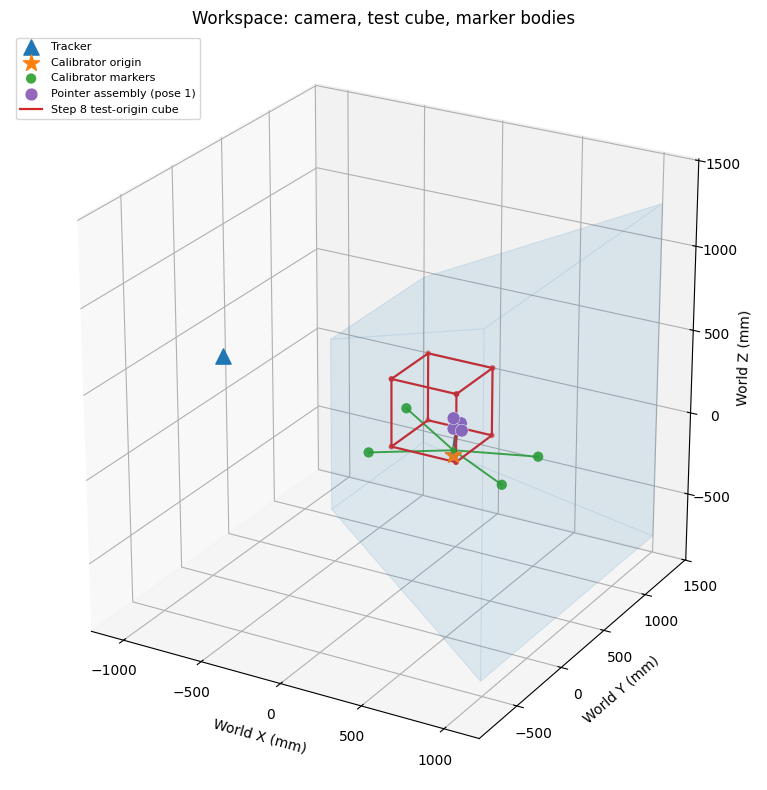

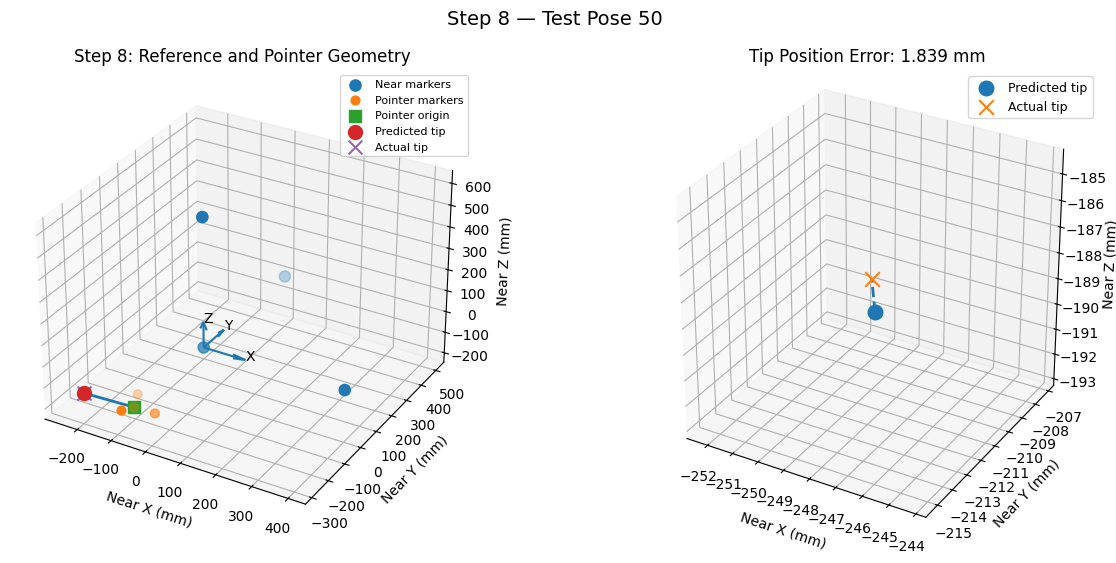

In [16]:
%matplotlib inline
import matplotlib.pyplot as plt
from IPython.display import display
from functions.workspace_viz import plot_workspace

fig, ax, report = plot_workspace(
    F_tracker_approx,
    F_cal_approx,
    ptr_local_positions,
    ptr_tip_approx,
    cal_local_positions,
    show=False,
    show_detail=False
)

display(fig)
plt.close(fig)\



def xyz(v):
    return np.asarray(v.vec, dtype=float).ravel()

near_markers = np.array([xyz(p) for p in near_local_positions])

F_ptr_in_near = F_near_obs.inv() * F_ptr_obs

ptr_origin = xyz(F_ptr_in_near * vct3(0, 0, 0))

ptr_markers = np.array([
    xyz(F_ptr_in_near * p)
    for p in ptr_local_positions
])

pred = xyz(p_predicted)
true = xyz(p_actual)

error = np.linalg.norm(pred - true)

fig = plt.figure(figsize=(13, 5.5))


ax1 = fig.add_subplot(121, projection="3d")

ax1.scatter(*near_markers.T, s=65, label="Near markers")
ax1.scatter(*ptr_markers.T, s=40, label="Pointer markers")
ax1.scatter(*ptr_origin, s=65, marker="s", label="Pointer origin")

ax1.scatter(*pred, s=100, marker="o", label="Predicted tip")
ax1.scatter(*true, s=100, marker="x", label="Actual tip")

ax1.plot(
    [ptr_origin[0], pred[0]],
    [ptr_origin[1], pred[1]],
    [ptr_origin[2], pred[2]],
    linewidth=2
)


axis_length = 120
for direction, name in zip(np.eye(3), ["X", "Y", "Z"]):
    ax1.quiver(
        0, 0, 0,
        *direction,
        length=axis_length,
        normalize=True
    )
    endpoint = direction * axis_length
    ax1.text(*endpoint, name)

ax1.set_title("Step 8: Reference and Pointer Geometry")
ax1.set_xlabel("Near X (mm)")
ax1.set_ylabel("Near Y (mm)")
ax1.set_zlabel("Near Z (mm)")
ax1.legend(fontsize=8, loc="best")


ax2 = fig.add_subplot(122, projection="3d")

ax2.scatter(*pred, s=110, marker="o", label="Predicted tip")
ax2.scatter(*true, s=110, marker="x", label="Actual tip")

ax2.plot(
    [pred[0], true[0]],
    [pred[1], true[1]],
    [pred[2], true[2]],
    linestyle="--",
    linewidth=2
)

center = (pred + true) / 2
radius = max(2.0, error * 2.5)

ax2.set_xlim(center[0] - radius, center[0] + radius)
ax2.set_ylim(center[1] - radius, center[1] + radius)
ax2.set_zlim(center[2] - radius, center[2] + radius)
ax2.set_box_aspect((1, 1, 1))

ax2.set_title(f"Tip Position Error: {error:.3f} mm")
ax2.set_xlabel("Near X (mm)")
ax2.set_ylabel("Near Y (mm)")
ax2.set_zlabel("Near Z (mm)")
ax2.legend(fontsize=9)

fig.suptitle(
    f"Step 8 — Test Pose {len(test_results)}",
    fontsize=14
)

plt.tight_layout()
display(fig)
plt.close(fig)


In [ ]:

import numpy as np

# Diagnostic only: ground truth is NOT used for calibration

p_tip_true = ptr.get_actual_tip_position().p

tip_calibration_error = (
    p_tip_est - p_tip_true
).norm()

valid_sensed = [
    s for s in sensed_tip_list
    if s is not None
]

training_residuals_diag = np.array([
    (
        F_cal.inv() * F_ptr * p_tip_est - sensed
    ).norm()
    for F_ptr, F_cal, sensed in zip(
        F_ptr_list,
        F_cal_list,
        sensed_tip_list
    )
    if sensed is not None
])

print("--- Abnormal Run Diagnostics ---")

print(
    "Valid calibration observations:",
    len(valid_sensed)
)

print(
    "Out-of-range readings in accepted dataset:",
    sum(s is None for s in sensed_tip_list)
)

print(
    "Maximum accepted sensor distance:",
    f"{max(s.norm() for s in valid_sensed):.4f} mm"
)

print(
    "Tip calibration coordinate error:",
    f"{tip_calibration_error:.4f} mm"
)

print(
    "Training mean residual:",
    f"{np.mean(training_residuals_diag):.4f} mm"
)

print(
    "Training residual RMSE:",
    f"{np.sqrt(np.mean(training_residuals_diag**2)):.4f} mm"
)

print(
    "Estimated tip standard deviations:",
    np.sqrt(np.diag(p_tip_cov))
)


In [ ]:

import numpy as np

# Diagnostic only. Do NOT rerun the calibration cells.
# Reuses the current marker geometry and calibration estimate.

N_DIAGNOSTIC = min(1000, len(test_poses))
p_true = ptr.get_actual_tip_position().p

near_total = []
near_tracking = []
cal_total = []
cal_tracking = []
error_dot = []

for F_nominal in test_poses[:N_DIAGNOSTIC]:

    test_placed = simulation.place_marker_body(
        ptr_mb, F_nominal, precision="precise"
    )

    # Exactly ONE simultaneous tracker observation
    obs = simulation.sample_marker_bodies(
        trk, [test_placed, near_placed, cal_placed]
    )

    Fp = obs["ptr_mb"].frame
    Fn = obs["near_mb"].frame
    Fc = obs["cal_mb"].frame

    Fp_true = test_placed.actual_placement
    Fn_true = near_placed.actual_placement
    Fc_true = cal_placed.actual_placement

    # Near reference
    p_near_pred = Fn.inv() * Fp * p_tip_est
    p_near_true = Fn_true.inv() * Fp_true * p_true
    p_near_track = Fn.inv() * Fp * p_true

    near_total.append(
        (p_near_pred - p_near_true).norm()
    )
    near_tracking.append(
        (p_near_track - p_near_true).norm()
    )

    # Calibrator reference
    p_cal_pred = Fc.inv() * Fp * p_tip_est
    p_cal_true = Fc_true.inv() * Fp_true * p_true
    p_cal_track = Fc.inv() * Fp * p_true

    cal_total.append(
        (p_cal_pred - p_cal_true).norm()
    )
    cal_tracking.append(
        (p_cal_track - p_cal_true).norm()
    )

    # Error interaction in the near-reference frame
    e_track = (
        p_near_track - p_near_true
    ).vec.ravel()

    e_cal = (
        p_near_pred - p_near_track
    ).vec.ravel()

    error_dot.append(np.dot(e_track, e_cal))


def report_errors(name, values):
    a = np.asarray(values)
    print(
        f"{name}: mean={a.mean():.4f} mm, "
        f"RMSE={np.sqrt(np.mean(a**2)):.4f} mm, "
        f"max={a.max():.4f} mm"
    )


print(f"Diagnostic samples: {N_DIAGNOSTIC}")
print(f"Local tip coordinate difference: "
      f"{(p_tip_est-p_true).norm():.4f} mm")

report_errors("Near total", near_total)
report_errors("Near tracking-only", near_tracking)
report_errors("Calibrator total", cal_total)
report_errors("Calibrator tracking-only", cal_tracking)

print(
    "Mean error dot product:",
    f"{np.mean(error_dot):.4f} mm^2"
)

print(
    "Near pass rate:",
    f"{100*np.mean(np.array(near_total)<=2):.2f}%"
)

print(
    "Calibrator pass rate:",
    f"{100*np.mean(np.array(cal_total)<=2):.2f}%"
)


In [ ]:

import numpy as np
from itertools import combinations

# Ground truth is used for DIAGNOSIS ONLY.

def diagnose_marker_model(placed):

    body = placed.body

    nominal = body.nominal_marker_positions
    actual = body.get_actual_marker_positions()

    # Best rigid alignment:
    # refined model coordinates -> actual marker coordinates
    F_align = trk.procrustes_solver(nominal, actual)

    R = F_align.R.matrix
    t = F_align.p.vec.ravel()

    cos_theta = np.clip(
        (np.trace(R) - 1) / 2, -1.0, 1.0
    )

    angle_deg = np.degrees(np.arccos(cos_theta))
    translation_mm = np.linalg.norm(t)

    def xyz(v):
        return np.asarray(v.vec).ravel()

    P = np.array([xyz(p) for p in nominal])
    Q = np.array([xyz(p.p) for p in actual])

    pairs = list(combinations(range(len(P)), 2))

    distance_errors = [
        np.linalg.norm(P[i] - P[j])
        - np.linalg.norm(Q[i] - Q[j])
        for i, j in pairs
    ]

    pair_rmse = np.sqrt(
        np.mean(np.square(distance_errors))
    )

    aligned_errors = [
        (F_align * p - q.p).norm()
        for p, q in zip(nominal, actual)
    ]

    shape_rmse = np.sqrt(
        np.mean(np.square(aligned_errors))
    )

    print(f"\n--- {body.name} ---")
    print(f"Pairwise distance RMSE: {pair_rmse:.4f} mm")
    print(f"Rigid alignment translation: {translation_mm:.4f} mm")
    print(f"Rigid alignment rotation: {angle_deg:.4f} deg")
    print(f"Post-alignment shape RMSE: {shape_rmse:.4f} mm")

    return F_align


F_ptr_align = diagnose_marker_model(ptr_placed)
F_cal_align = diagnose_marker_model(cal_placed)
F_near_align = diagnose_marker_model(near_placed)

# Optional: compare tip estimates after aligning
# the pointer's refined marker coordinate model.
p_tip_aligned = F_ptr_align * p_tip_est
p_tip_true = ptr.get_actual_tip_position().p

print(
    "\nTip difference after pointer model alignment:",
    f"{(p_tip_aligned-p_tip_true).norm():.4f} mm"
)


In [ ]:

import numpy as np

N_DIAGNOSTIC = min(1000, len(test_poses))

near_raw_errors = []
near_aligned_errors = []

cal_raw_errors = []
cal_aligned_errors = []

for F_nominal in test_poses[:N_DIAGNOSTIC]:

    test_placed = simulation.place_marker_body(
        ptr_mb,
        F_nominal,
        precision="precise"
    )

    # One simultaneous tracker observation
    obs = simulation.sample_marker_bodies(
        trk,
        [test_placed, near_placed, cal_placed]
    )

    Fp = obs["ptr_mb"].frame
    Fn = obs["near_mb"].frame
    Fc = obs["cal_mb"].frame

    Fp_true = test_placed.actual_placement
    Fn_true = near_placed.actual_placement
    Fc_true = cal_placed.actual_placement

    p_true = ptr.get_actual_tip_position().p

    # Prediction in refined reference coordinates
    p_near_pred = Fn.inv() * Fp * p_tip_est
    p_cal_pred = Fc.inv() * Fp * p_tip_est

    # Ground truth in actual reference coordinates
    p_near_true = Fn_true.inv() * Fp_true * p_true
    p_cal_true = Fc_true.inv() * Fp_true * p_true

    # Original evaluation
    near_raw_errors.append(
        (p_near_pred - p_near_true).norm()
    )
    cal_raw_errors.append(
        (p_cal_pred - p_cal_true).norm()
    )

    # Diagnostic-only coordinate-frame alignment
    p_near_aligned = F_near_align * p_near_pred
    p_cal_aligned = F_cal_align * p_cal_pred

    near_aligned_errors.append(
        (p_near_aligned - p_near_true).norm()
    )
    cal_aligned_errors.append(
        (p_cal_aligned - p_cal_true).norm()
    )


def summarize(name, values):
    e = np.array(values)
    print(
        f"{name}: "
        f"mean={e.mean():.4f} mm, "
        f"RMSE={np.sqrt(np.mean(e**2)):.4f} mm, "
        f"pass={100*np.mean(e<=2):.2f}%"
    )


print("--- Coordinate Frame Consistency ---")
print(f"Diagnostic poses: {N_DIAGNOSTIC}")

summarize("Near RAW", near_raw_errors)
summarize("Near ALIGNED", near_aligned_errors)

summarize("Cal RAW", cal_raw_errors)
summarize("Cal ALIGNED", cal_aligned_errors)
